Author: Aparajita Nath

Product: compare the models after tuning them one by one: ROC-AUC, Gini, Brier score and calibration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import helpers as h

pd.set_option("display.max_columns", 30)

## 4. Compare the models

### 4.1 Load the saved predictions

In [2]:
names = {"LR": "Logistic regression", "CART": "CART tree", "RF": "Random forest"}
preds = {}
for key, label in names.items():
    d = pd.read_csv(h.OUTPUTS / f"preds_{key}.csv", index_col=0)
    preds[label] = d["pd_pred"].to_numpy()
    y_test = d["bad_credit"]          # same test cases and order in every file
print({k: len(v) for k, v in preds.items()}, f"| test cases: {len(y_test)}, bad: {int(y_test.sum())}")

{'Logistic regression': 300, 'CART tree': 300, 'Random forest': 300} | test cases: 300, bad: 90


### 4.2 Performance table

The interval is a 95% bootstrap interval on the test set.

In [3]:
results = pd.DataFrame([h.evaluate(y_test, p, name) for name, p in preds.items()]).set_index("model")
results.to_csv(h.OUTPUTS / "model_metrics.csv")
results.round(3)

,roc_auc,auc_95ci_low,auc_95ci_high,gini,brier_score,mean_predicted_pd,observed_bad_rate
model,,,,,,,
Logistic regression,0.768,0.710,0.824,0.535,0.169,0.308,0.3
CART tree,0.722,0.662,0.775,0.444,0.183,0.318,0.3
Random forest,0.789,0.733,0.842,0.579,0.167,0.310,0.3


### 4.3 Discrimination and calibration

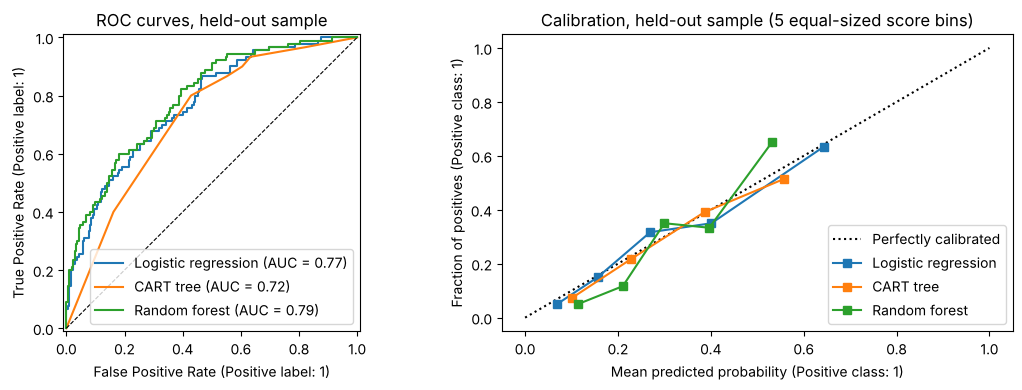

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
h.plot_roc(y_test, preds, axes[0])
h.plot_calibration(y_test, preds, axes[1])
fig.tight_layout()
fig.savefig(h.FIGURES / "model_performance.png", dpi=160)
plt.show()

In [5]:
for name, p in preds.items():
    print(name)
    print(h.calibration_table(y_test, p).round(3).to_string(), "\n")

Logistic regression
           cases  mean_predicted_pd  observed_bad_rate
score_bin                                             
Bin 1         60              0.069              0.050
Bin 2         60              0.156              0.150
Bin 3         60              0.269              0.317
Bin 4         60              0.401              0.350
Bin 5         60              0.643              0.633 

CART tree
           cases  mean_predicted_pd  observed_bad_rate
score_bin                                             
Bin 1         60              0.081              0.050
Bin 2         60              0.194              0.200
Bin 3         60              0.344              0.283
Bin 4         60              0.415              0.433
Bin 5         60              0.558              0.533 

Random forest
           cases  mean_predicted_pd  observed_bad_rate
score_bin                                             
Bin 1         60              0.114              0.050
Bin 2         60 

### 4.4 What the comparison shows

- **Ranking:** the random forest has the highest ROC-AUC (0.789, Gini 0.579), followed by the logistic regression (0.768, Gini 0.535) and the CART tree (0.722, Gini 0.444). The 95% intervals of the random forest and the logistic regression (0.733-0.842 and 0.710-0.824) overlap heavily, so with 300 test cases and 90 bad credits there is no clear evidence that one ranks better than the other. The tree is lower, which is expected: the selected tree has depth 3, so it can produce at most 8 different scores.
- **Probability accuracy:** the Brier scores are 0.167 (random forest), 0.169 (logistic regression) and 0.183 (CART tree). The first two are almost the same.
- **Calibration:** in five score bins of 60 cases each, the logistic regression's predicted PD is close to the observed bad rate in the highest bin (64% against 63%) and the lowest (7% against 5%). The random forest predicts too high in the two lowest bins (11% against 5% and 21% against 12%) and too low in the highest (53% against 65%). With 60 cases per bin these gaps are noisy.
- **Choice for monitoring:** the logistic regression is nearly as good as the random forest here and is much easier to explain, so notebook E monitors it.
- **Caution:** all comparisons use one split of a small dataset. Treat the model ranking as indicative only.